<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
!pip install captum shap lime scikit-image grad-cam --quiet
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

# Captum for attributions (Integrated Gradients, Occlusion, GuidedBackprop)
from captum.attr import IntegratedGradients, Occlusion, GuidedBackprop

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.DEFAULT

model = resnet50(weights=weights)

model = model.eval().to(device)

preprocess = weights.transforms()

imagenet_labels = weights.meta["categories"]


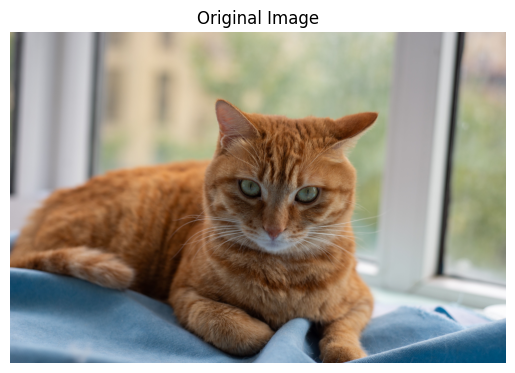

In [ ]:
# Example image: a dog (change if you like)
IMAGE_URL = "https://images.pexels.com/photos/34345889/pexels-photo-34345889.jpeg"

# Download the image from the internet
response = requests.get(IMAGE_URL)

# Convert downloaded data into a PIL RGB image
img_pil = Image.open(BytesIO(response.content)).convert("RGB")

# Display the image
plt.imshow(img_pil)

# Hide x-axis and y-axis
plt.axis("off")

# Add title
plt.title("Original Image")

# Display the final figure
plt.show()

In [ ]:
def prepare_image(img_pil):
    # preprocess returns a tensor [C,H,W], we need [1,C,H,W]
    input_tensor = preprocess(img_pil).unsqueeze(0).to(device)
    return input_tensor


def predict(input_tensor):
    with torch.no_grad():
        logits = model(input_tensor)

    probs = logits.softmax(dim=1)
    return probs, logits


input_tensor = prepare_image(img_pil)

probs, logits = predict(input_tensor)

top_prob, top_idx = probs.max(dim=1)

pred_label = imagenet_labels[top_idx.item()]

print(f"Top prediction: {pred_label} (prob={top_prob.item():.3f})")

Top prediction: tiger cat (prob=0.327)


In [ ]:
# Create an Occlusion explainer using our ResNet50 model
occlusion = Occlusion(model)

# We are not training the model, so gradient tracking is not required
input_tensor.requires_grad = False

# Select the class predicted by ResNet50
target = top_idx.item()

# Perform Occlusion analysis
# Window size = 15 × 15 pixels
# Stride = 8 pixels
attributions_occ = occlusion.attribute(
    input_tensor,
    strides=(1, 8, 8),
    target=target,
    sliding_window_shapes=(1, 15, 15),
    baselines=0
)

# Remove unnecessary dimensions
# Detach from PyTorch computation graph
# Move data to CPU
# Convert PyTorch tensor to NumPy array
attr_occ = attributions_occ.squeeze().detach().cpu().numpy()

# Combine attribution values across the color channels
attr_occ = attr_occ.sum(axis=0)

# Normalize attribution values to approximately 0–1
attr_occ_norm = (attr_occ - attr_occ.min()) / (
    attr_occ.max() - attr_occ.min() + 1e-8
)

# Create a figure for visualization
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

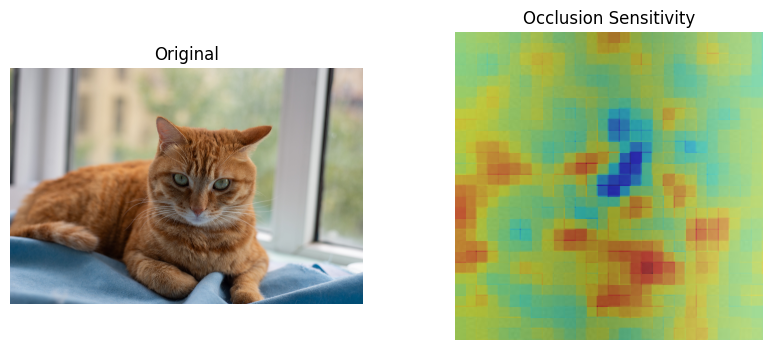

In [ ]:
# Occlusion parameters
# Sliding window size: 15x15, stride: 8
attributions_occ = occlusion.attribute(
    input_tensor,
    strides=(1, 8, 8),
    target=target,
    sliding_window_shapes=(1, 15, 15),
    baselines=0
)

# Aggregate over channels (sum)
attr_occ = attributions_occ.squeeze().detach().cpu().numpy()
attr_occ = attr_occ.sum(axis=0)

# Normalize for visualization
attr_occ_norm = (attr_occ - attr_occ.min()) / (
    attr_occ.max() - attr_occ.min() + 1e-8
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_pil)
plt.imshow(attr_occ_norm, cmap="jet", alpha=0.5)
plt.title("Occlusion Sensitivity")
plt.axis("off")

plt.show()

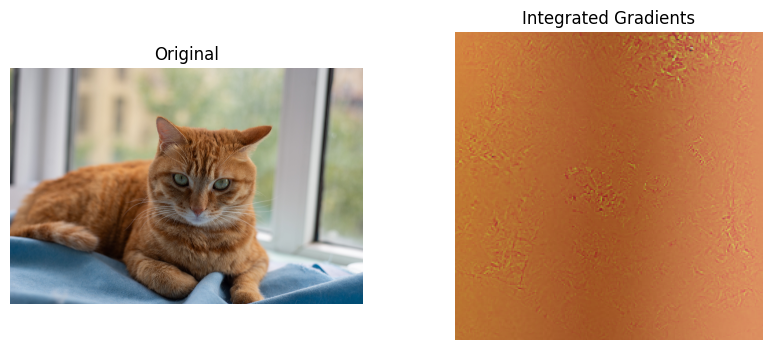

In [ ]:
# Create Integrated Gradients explainer for the ResNet50 model
ig = IntegratedGradients(model)

# Create a zero-valued baseline with the same shape as the input
baseline = torch.zeros_like(input_tensor).to(device)

# Calculate Integrated Gradients attributions
attributions_ig = ig.attribute(
    input_tensor,
    baselines=baseline,
    target=target,
    n_steps=50
)

# Remove unnecessary dimensions
# Disconnect from computation graph
# Move to CPU
# Convert to NumPy
attr_ig = attributions_ig.squeeze().detach().cpu().numpy()

# Combine RGB channel attributions
attr_ig = attr_ig.sum(axis=0)

# Normalize values to approximately 0–1
attr_ig_norm = (attr_ig - attr_ig.min()) / (
    attr_ig.max() - attr_ig.min() + 1e-8
)

# Create figure
plt.figure(figsize=(10, 4))

# First subplot: original image
plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

# Second subplot: Integrated Gradients explanation
plt.subplot(1, 2, 2)
plt.imshow(img_pil)
plt.imshow(attr_ig_norm, cmap="hot", alpha=0.5)
plt.title("Integrated Gradients")
plt.axis("off")

# Display the figure
plt.show()

/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


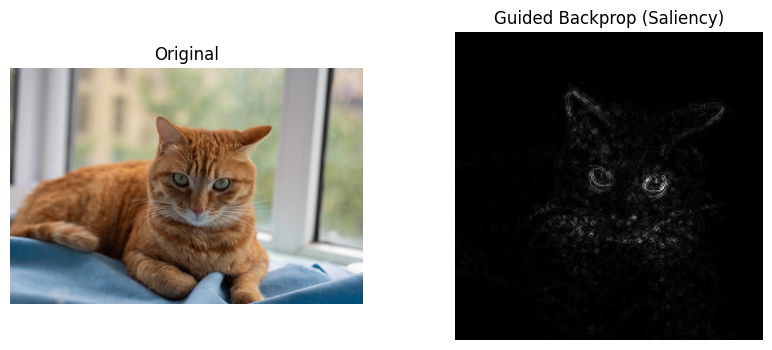

In [ ]:
# Create Guided Backpropagation explainer
gbp = GuidedBackprop(model)

# Enable gradient calculation for the input image
input_tensor.requires_grad = True

# Calculate Guided Backpropagation attributions
attributions_gbp = gbp.attribute(
    input_tensor,
    target=target
)

# Remove unnecessary dimensions
# Detach from computation graph
# Move tensor to CPU
# Convert to NumPy array
attr_gbp = attributions_gbp.squeeze().detach().cpu().numpy()

# Take absolute values and combine the RGB channels
attr_gbp = np.abs(attr_gbp).sum(axis=0)

# Normalize saliency values to approximately 0–1
attr_gbp_norm = (attr_gbp - attr_gbp.min()) / (
    attr_gbp.max() - attr_gbp.min() + 1e-8
)

# Create a figure
plt.figure(figsize=(10, 4))

# First image: Original
plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

# Second image: Guided Backpropagation
plt.subplot(1, 2, 2)
plt.imshow(attr_gbp_norm, cmap="gray")
plt.title("Guided Backprop (Saliency)")
plt.axis("off")

# Display the final result
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Make sure model & input are ready
model.eval()
model.to(device)
input_tensor = input_tensor.to(device)  # [1,3,H,W]

# 1. Choose target conv layer (last block of ResNet-50)
target_layers = [model.layer4[-1]]

# 2. Create Grad-CAM object
cam = GradCAM(
    model=model,
    target_layers=target_layers
    # use_cuda=(device.type == "cuda")  # if your version complains, just drop this arg
)

# 3. Target class (top predicted class)
targets = [ClassifierOutputTarget(target)]

# 4. Compute Grad-CAM mask
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]  # [H_cam, W_cam]

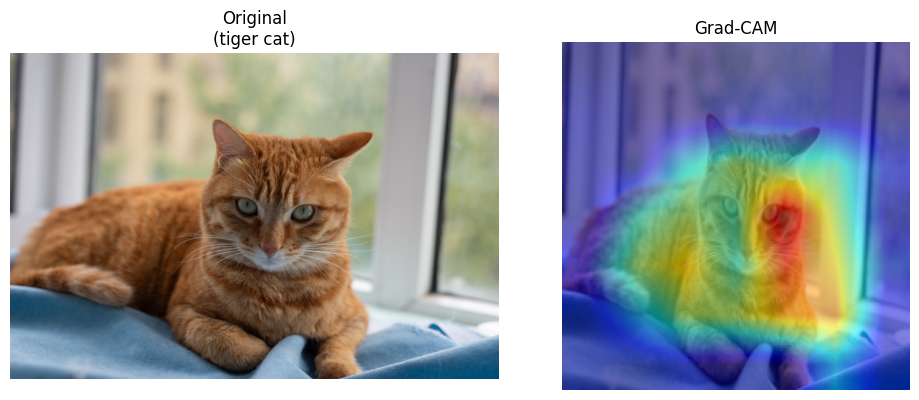

In [ ]:
# 5. Resize the original image to the same size as the mask
H_cam, W_cam = grayscale_cam.shape
img_resized = img_pil.resize((W_cam, H_cam))  # PIL wants (width, height)

rgb_img = np.array(img_resized).astype(np.float32) / 255.0  # [H_cam, W_cam, 3]

# 6. Overlay heatmap on resized image
visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

# 7. Plot both original and Grad-CAM visualization
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
model.to(device)
input_tensor = input_tensor.to(device)

# 1. Target layer (same as Grad-CAM)
target_layers = [model.layer4[-1]]

# 2. Create Grad-CAM++ object
cam_pp = GradCAMPlusPlus(
    model=model,
    target_layers=target_layers
    # use_cuda=(device.type == "cuda")  # drop this arg if your version complains
)

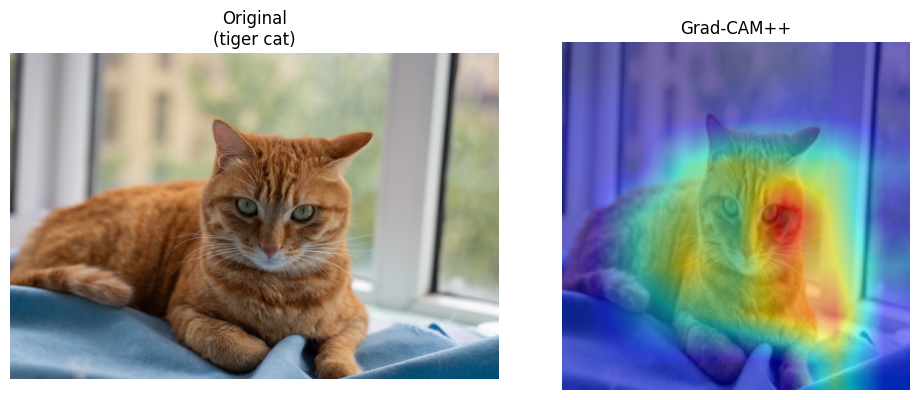

In [ ]:
# 3. Target class: same 'target' as before
targets = [ClassifierOutputTarget(target)]

# 4. Compute Grad-CAM++ mask
grayscale_cam_pp = cam_pp(
    input_tensor=input_tensor,
    targets=targets
)[0]  # [H_cam, W_cam]

# 5. Resize original image to mask size
H_cam, W_cam = grayscale_cam_pp.shape

img_resized_pp = img_pil.resize((W_cam, H_cam))

rgb_img_pp = np.array(img_resized_pp).astype(
    np.float32
) / 255.0

# 6. Overlay heatmap
visualization_pp = show_cam_on_image(
    rgb_img_pp,
    grayscale_cam_pp,
    use_rgb=True
)

# 7. Plot
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization_pp)
plt.title("Grad-CAM++")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
# 1. Function that LIME will use to query the model
def batch_predict(images):
    """
    images: list/array of images as float32 in [0,1], shape (H,W,3)
    returns: numpy array of probabilities [N, num_classes]
    """
    model.eval()
    batch_tensors = []

    for img in images:
        # img is HWC, float [0,1] → uint8 → PIL
        pil = Image.fromarray((img * 255).astype(np.uint8))
        t = preprocess(pil)                         # [3,224,224]
        batch_tensors.append(t)

    batch = torch.stack(batch_tensors).to(device)  # [N,3,224,224]

    with torch.no_grad():
        logits = model(batch)
        probs = logits.softmax(dim=1)

    return probs.cpu().numpy()


# 2. Prepare the original image for LIME (HWC, float in [0,1])
img_lime = np.array(img_pil).astype(np.float32) / 255.0

In [ ]:
# 3. Create the LIME image explainer
explainer = lime_image.LimeImageExplainer()

# This step can take a bit of time (num_samples perturbations)
explanation = explainer.explain_instance(
    img_lime,
    batch_predict,
    top_labels=5,
    hide_color=0,
    num_samples=20
)

# 4. Choose which class to explain (use same 'target' as Grad-CAM)
lime_label = target    # or explanation.top_labels[0]

# Get an image & mask of the important superpixels
temp, mask = explanation.get_image_and_mask(
    lime_label,
    positive_only=True,
    num_features=5,     # number of superpixels to highlight
    hide_rest=False
)

# 5. Visualize
plt.figure(figsize=(10, 4))

  0%|          | 0/20 [00:00<?, ?it/s]

In [ ]:
# 5. Visualize
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME - important superpixels")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision.transforms as T

model.eval()
model.to(device)
input_tensor = input_tensor.to(device)  # [1,3,H,W]

# 1. Build a small background dataset (random crops of the same image)
background_images = []

bg_transform = T.Compose([
    T.RandomResizedCrop(size=img_pil.size[0], scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(),
])

for _ in range(20):          # 20 background samples is enough for a demo
    bg_pil = bg_transform(img_pil)
    bg_tensor = preprocess(bg_pil)       # [3,224,224]
    background_images.append(bg_tensor)
    background = torch.stack(background_images).to(device)  # [20,3,224,224]

# 2. Create DeepExplainer
explainer_shap = shap.DeepExplainer(model, background)

# 3. Compute SHAP values for the current image
#
# shap_values is a list of length = num_classes (1000 for ImageNet)
shap_values = explainer_shap.shap_values(input_tensor)

# 4. Take SHAP values for the target class
#
# shap_values[target]: [1, 3, H, W]
sv = shap_values[target][0]  # [3,H,W]

# Aggregate over color channels (mean)
sv_agg = sv.mean(axis=0)       # [H,W]
sv_agg = sv_agg.cpu().numpy()  # [H,W]

# Normalize to [-1,1] for visualization
max_abs = np.max(np.abs(sv_agg)) + 1e-8
sv_norm = sv_agg / max_abs    # now in [-1,1]

# 5. Resize original image to same size as SHAP map
# (should already be 224x224)
H_shap, W_shap = sv_norm.shape
img_resized_shap = img_pil.resize((W_shap, H_shap))

rgb_img_shap = np.array(img_resized_shap).astype(
    np.float32
) / 255.0

# 6. Plot
plt.figure(figsize=(12, 4))# 6. Plot
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sv_norm, cmap="bwr")
plt.colorbar(fraction=0.046, pad=0.04)
plt.title("SHAP (raw map)\nred=positive, blue=negative")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(rgb_img_shap)
plt.imshow(sv_norm, cmap="bwr", alpha=0.5)
plt.title("SHAP overlay")
plt.axis("off")

plt.tight_layout()
plt.show()